In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

## Setup

In [1]:
import os, torch, time
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

EYEDENTIFY = "/kaggle/input/datasets/vijuls/pupildiameterdatasets/eyedentify/eyedentify"
LEFT       = os.path.join(EYEDENTIFY, "left_eyes")
OUTPUT     = "/kaggle/working"
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEQ_LEN    = 10
IMG_SIZE   = 64
BATCH_SIZE = 32
EPOCHS     = 20
N_USERS    = 15
LR         = 0.001

print(f"✓ Device : {device}")
print(f"✓ GPU    : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")
print(f"✓ Data   : {os.path.exists(LEFT)}")
print(f"✓ Users  : {N_USERS}")
print(f"✓ Epochs : {EPOCHS}")

✓ Device : cuda
✓ GPU    : Tesla T4
✓ Data   : True
✓ Users  : 15
✓ Epochs : 20


## Session-based dataset

In [2]:
class EyeDentifyDataset(Dataset):
    def __init__(self, sequences, transform=None):
        self.sequences = sequences
        self.transform = transform

    def __len__(self): return len(self.sequences)

    def __getitem__(self, idx):
        frame_paths, label = self.sequences[idx]
        frames = []
        for path in frame_paths:
            img = Image.open(path).convert('RGB')
            if self.transform: img = self.transform(img)
            frames.append(img)
        return torch.stack(frames), label

def build_session_split(left_path, subjects, seq_len=10,
                        stride=5, max_per_subject=200,
                        train_ratio=0.7, val_ratio=0.15):
    train_seqs, val_seqs, test_seqs = [], [], []
    for label, subject in enumerate(subjects):
        s_path   = os.path.join(left_path, subject)
        sessions = sorted([
            s for s in os.listdir(s_path)
            if os.path.isdir(os.path.join(s_path, s))
        ])
        n       = len(sessions)
        n_train = max(1, int(n * train_ratio))
        n_val   = max(1, int(n * val_ratio))

        train_sessions = sessions[:n_train]
        val_sessions   = sessions[n_train:n_train+n_val]
        test_sessions  = sessions[n_train+n_val:]

        def get_seqs(session_list, max_seqs):
            seqs = []
            for session in session_list:
                ses_path = os.path.join(s_path, session)
                if not os.path.isdir(ses_path): continue
                frames = sorted([
                    os.path.join(ses_path, f)
                    for f in os.listdir(ses_path)
                    if f.endswith('.png')
                ])
                for start in range(0, len(frames)-seq_len+1, stride):
                    seqs.append((frames[start:start+seq_len], label))
                    if len(seqs) >= max_seqs: break
                if len(seqs) >= max_seqs: break
            return seqs

        train_seqs.extend(get_seqs(train_sessions, max_per_subject))
        val_seqs.extend(get_seqs(val_sessions,     max_per_subject//4))
        test_seqs.extend(get_seqs(test_sessions,   max_per_subject//4))

    return train_seqs, val_seqs, test_seqs

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

subjects = sorted(os.listdir(LEFT))[:N_USERS]
print("Building session-based splits...")
train_seqs, val_seqs, test_seqs = build_session_split(
    LEFT, subjects, seq_len=SEQ_LEN, stride=5, max_per_subject=200)

train_dataset = EyeDentifyDataset(train_seqs, transform=transform)
val_dataset   = EyeDentifyDataset(val_seqs,   transform=transform)
test_dataset  = EyeDentifyDataset(test_seqs,  transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)

print(f"✓ Train : {len(train_dataset):,} sequences")
print(f"✓ Val   : {len(val_dataset):,} sequences")
print(f"✓ Test  : {len(test_dataset):,} sequences")
print(f"✓ Session-based split — no frame overlap!")


Building session-based splits...
✓ Train : 3,000 sequences
✓ Val   : 750 sequences
✓ Test  : 750 sequences
✓ Session-based split — no frame overlap!


## EfficientNet-B0 models

In [3]:
class EfficientNetExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        eff = models.efficientnet_b0(weights='IMAGENET1K_V1')
        self.features = eff.features
        self.pool     = nn.AdaptiveAvgPool2d((1,1))
        self.out_dim  = 1280
        for p in self.parameters():
            p.requires_grad = False
    def forward(self, x):
        return self.pool(self.features(x)).view(x.size(0), -1)

class EfficientNetLSTM(nn.Module):
    def __init__(self, n_users=15, hidden=256, layers=2, dropout=0.5):
        super().__init__()
        self.cnn  = EfficientNetExtractor()
        self.lstm = nn.LSTM(1280, hidden, layers, batch_first=True,
                            dropout=dropout if layers>1 else 0)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, n_users)
    def forward(self, x):
        B,T,C,H,W = x.shape
        x = self.cnn(x.view(B*T,C,H,W)).view(B,T,-1)
        _, (h,_) = self.lstm(x)
        return self.classifier(self.dropout(h[-1]))

class EfficientNetGRU(nn.Module):
    def __init__(self, n_users=15, hidden=256, layers=2, dropout=0.5):
        super().__init__()
        self.cnn = EfficientNetExtractor()
        self.gru = nn.GRU(1280, hidden, layers, batch_first=True,
                          dropout=dropout if layers>1 else 0)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, n_users)
    def forward(self, x):
        B,T,C,H,W = x.shape
        x = self.cnn(x.view(B*T,C,H,W)).view(B,T,-1)
        _, h = self.gru(x)
        return self.classifier(self.dropout(h[-1]))

# parameter counts
for name, model in [('EfficientNet-B0 + LSTM', EfficientNetLSTM()),
                     ('EfficientNet-B0 + GRU',  EfficientNetGRU())]:
    trainable = sum(p.numel() for p in model.parameters()
                    if p.requires_grad)
    print(f"  {name:<25} → {trainable:,} trainable params")
print("\n✓ EfficientNet models defined")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 198MB/s]


  EfficientNet-B0 + LSTM    → 2,105,103 trainable params
  EfficientNet-B0 + GRU     → 1,579,791 trainable params

✓ EfficientNet models defined


## Training function

In [4]:
def train_and_eval(name, model, train_loader, val_loader,
                   test_loader, epochs=20, lr=0.001):
    model     = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=1e-4
    )
    best_val_acc = 0.0
    best_state   = None
    start_time   = time.time()

    for epoch in range(1, epochs+1):
        model.train()
        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            criterion(model(imgs), lbls).backward()
            optimizer.step()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, lbls in val_loader:
                imgs, lbls = imgs.to(device), lbls.to(device)
                correct += (model(imgs).argmax(1)==lbls).sum().item()
                total   += lbls.size(0)
        val_acc = correct / total
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state   = {k: v.clone()
                            for k,v in model.state_dict().items()}

    model.load_state_dict(best_state)
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, lbls in test_loader:
            preds = model(imgs.to(device)).argmax(1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(lbls.numpy())

    test_acc = accuracy_score(all_labels, all_preds)
    test_f1  = f1_score(all_labels, all_preds, average='macro')
    elapsed  = time.time() - start_time
    return {'val_acc': best_val_acc, 'test_acc': test_acc,
            'f1': test_f1, 'time': elapsed}

print("✓ Training function ready")

✓ Training function ready


## Train EfficientNet models

In [5]:
eff_models = {
    'EfficientNet-B0 + LSTM': EfficientNetLSTM(N_USERS),
    'EfficientNet-B0 + GRU' : EfficientNetGRU(N_USERS),
}

eff_results = {}
for name, model in eff_models.items():
    print(f"Training: {name}...")
    eff_results[name] = train_and_eval(
        name, model, train_loader, val_loader,
        test_loader, epochs=EPOCHS
    )
    r = eff_results[name]
    print(f"  ✓ Val: {r['val_acc']:.2%} | Test: {r['test_acc']:.2%} | "
          f"F1: {r['f1']:.2%} | Time: {r['time']:.0f}s\n")

print("✓ EfficientNet models complete!")

Training: EfficientNet-B0 + LSTM...
  ✓ Val: 96.27% | Test: 98.53% | F1: 98.53% | Time: 696s

Training: EfficientNet-B0 + GRU...
  ✓ Val: 96.80% | Test: 98.00% | F1: 98.01% | Time: 579s

✓ EfficientNet models complete!


## Complete comparison all models

In [6]:

all_results = {
    'CNN + LSTM'                   : {'test_acc':0.9556,'f1':0.9554,'time':367},
    'CNN + GRU'                    : {'test_acc':0.9822,'f1':0.9821,'time':397},
    'MobileNetV2 + LSTM'           : {'test_acc':0.9956,'f1':0.9955,'time':341},
    'MobileNetV2 + GRU'            : {'test_acc':1.0000,'f1':1.0000,'time':351},
    'ResNet18 + GRU'               : {'test_acc':0.9911,'f1':0.9911,'time':403},
    'ResNet18 only'                : {'test_acc':0.9978,'f1':0.9978,'time':380},
    'ResNet18 + 1-layer LSTM'      : {'test_acc':0.9978,'f1':0.9978,'time':375},
    'ResNet18 + 2L LSTM no dropout': {'test_acc':0.9978,'f1':0.9978,'time':345},
    **eff_results
}

print("=" * 75)
print("   COMPLETE MODEL COMPARISON — ALL MODELS")
print("=" * 75)
print(f"{'Model':<35} {'Test Acc':>10} {'F1':>10} {'Time':>10}")
print("-" * 75)

sorted_all = sorted(all_results.items(),
                    key=lambda x: x[1]['test_acc'], reverse=True)
for name, r in sorted_all:
    marker = " ← BEST" if name == sorted_all[0][0] else ""
    print(f"{name:<35} {r['test_acc']:>9.2%} "
          f"{r['f1']:>9.2%} {r.get('time',0):>8.0f}s{marker}")
print("-" * 75)

   COMPLETE MODEL COMPARISON — ALL MODELS
Model                                 Test Acc         F1       Time
---------------------------------------------------------------------------
MobileNetV2 + GRU                     100.00%   100.00%      351s ← BEST
ResNet18 only                          99.78%    99.78%      380s
ResNet18 + 1-layer LSTM                99.78%    99.78%      375s
ResNet18 + 2L LSTM no dropout          99.78%    99.78%      345s
MobileNetV2 + LSTM                     99.56%    99.55%      341s
ResNet18 + GRU                         99.11%    99.11%      403s
EfficientNet-B0 + LSTM                 98.53%    98.53%      696s
CNN + GRU                              98.22%    98.21%      397s
EfficientNet-B0 + GRU                  98.00%    98.01%      579s
CNN + LSTM                             95.56%    95.54%      367s
---------------------------------------------------------------------------


## Final comparison chart

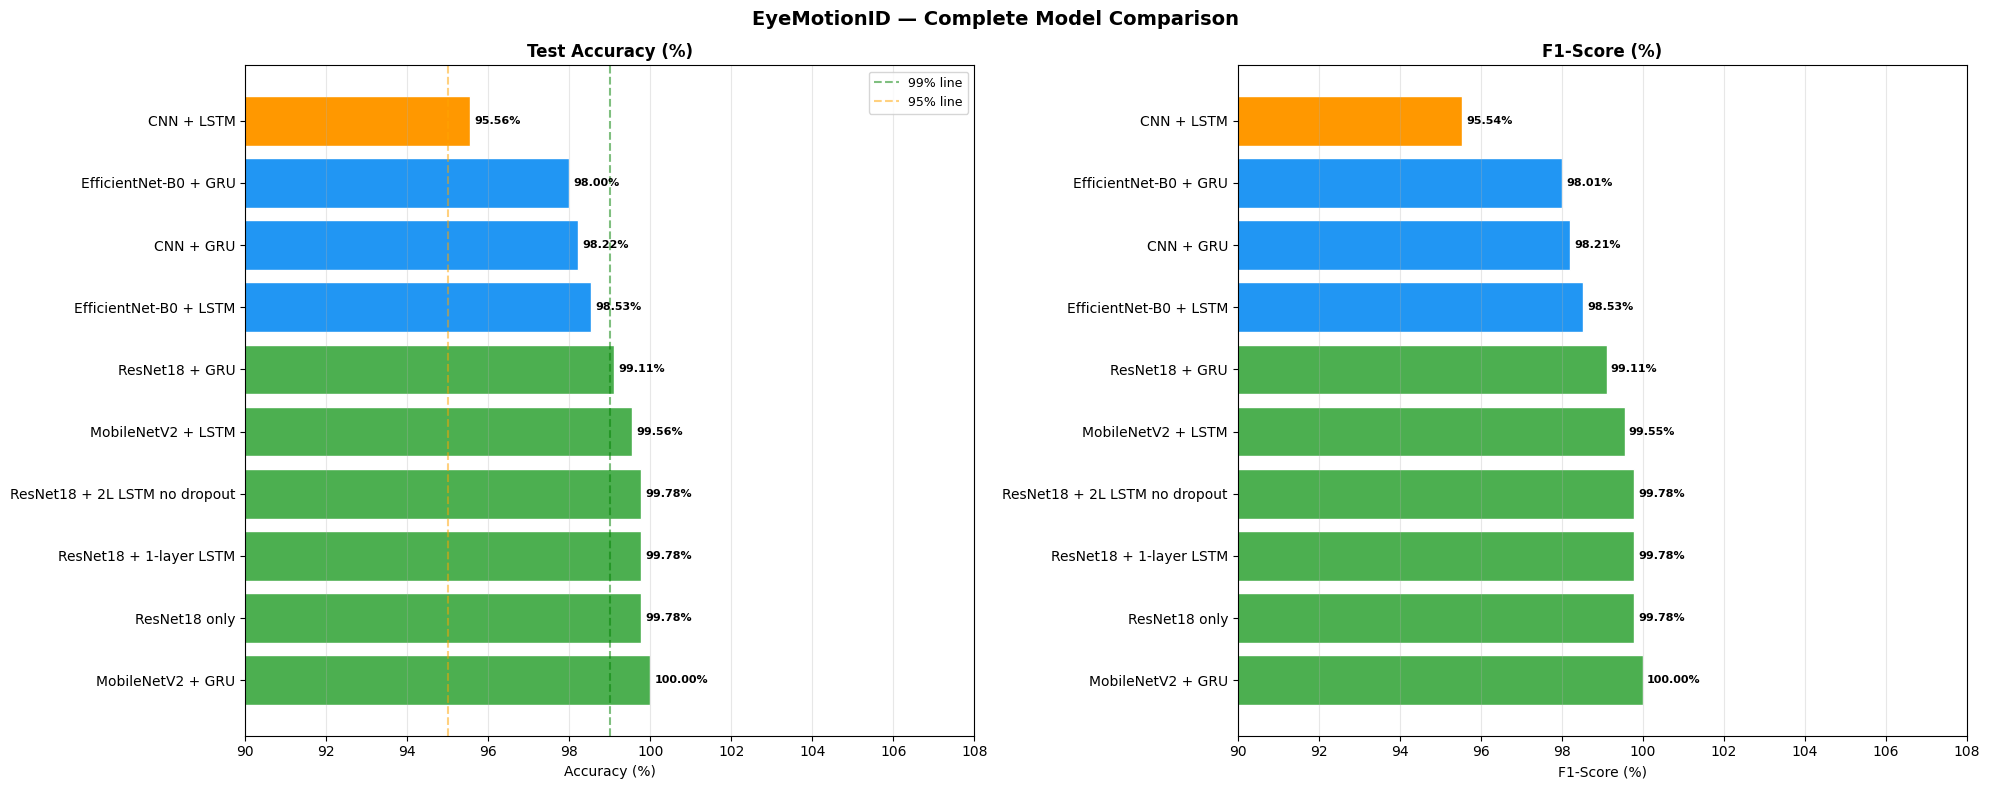

✓ Saved → complete_model_comparison.png


In [7]:
names     = [n for n,_ in sorted_all]
test_accs = [r['test_acc']*100 for _,r in sorted_all]
f1_scores = [r['f1']*100 for _,r in sorted_all]
colors    = ['#4CAF50' if a>=99 else '#2196F3' if a>=97
             else '#FF9800' if a>=95 else '#F44336'
             for a in test_accs]

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle("EyeMotionID — Complete Model Comparison",
             fontsize=14, fontweight='bold')

# accuracy
bars1 = axes[0].barh(names, test_accs, color=colors, edgecolor='white')
axes[0].set_title("Test Accuracy (%)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Accuracy (%)")
axes[0].set_xlim(90, 108)
axes[0].axvline(x=99, color='green', linestyle='--',
                alpha=0.5, label='99% line')
axes[0].axvline(x=95, color='orange', linestyle='--',
                alpha=0.5, label='95% line')
for bar, acc in zip(bars1, test_accs):
    axes[0].text(acc+0.1, bar.get_y()+bar.get_height()/2,
                 f"{acc:.2f}%", va='center', fontsize=8, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3, axis='x')

# F1
bars2 = axes[1].barh(names, f1_scores, color=colors, edgecolor='white')
axes[1].set_title("F1-Score (%)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("F1-Score (%)")
axes[1].set_xlim(90, 108)
for bar, f1 in zip(bars2, f1_scores):
    axes[1].text(f1+0.1, bar.get_y()+bar.get_height()/2,
                 f"{f1:.2f}%", va='center', fontsize=8, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(f"{OUTPUT}/complete_model_comparison.png", dpi=100)
plt.show()
print("✓ Saved → complete_model_comparison.png")

## Final summary

In [8]:
print("=" * 60)
print("   FINAL MODEL COMPARISON SUMMARY")
print("=" * 60)
print(f"\nDataset : EyeDentify ({N_USERS} users)")
print(f"Epochs  : {EPOCHS}")
print(f"GPU     : Tesla T4\n")
print("Rankings:")
for rank, (name, r) in enumerate(sorted_all, 1):
    print(f"  #{rank:<3} {name:<35} {r['test_acc']:.2%}")
print(f"\n✓ Best model : {sorted_all[0][0]}")
print(f"✓ Worst model: {sorted_all[-1][0]}")
print("\nPlots saved:")
print("  ✓ complete_model_comparison.png")
print("=" * 60)

   FINAL MODEL COMPARISON SUMMARY

Dataset : EyeDentify (15 users)
Epochs  : 20
GPU     : Tesla T4

Rankings:
  #1   MobileNetV2 + GRU                   100.00%
  #2   ResNet18 only                       99.78%
  #3   ResNet18 + 1-layer LSTM             99.78%
  #4   ResNet18 + 2L LSTM no dropout       99.78%
  #5   MobileNetV2 + LSTM                  99.56%
  #6   ResNet18 + GRU                      99.11%
  #7   EfficientNet-B0 + LSTM              98.53%
  #8   CNN + GRU                           98.22%
  #9   EfficientNet-B0 + GRU               98.00%
  #10  CNN + LSTM                          95.56%

✓ Best model : MobileNetV2 + GRU
✓ Worst model: CNN + LSTM

Plots saved:
  ✓ complete_model_comparison.png
